# Bradley Terry MLE in PyTorch



In [8]:
import sys
import time
from pathlib import Path
from datetime import datetime
from dataclasses import dataclass, field
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from torch.utils.tensorboard import SummaryWriter
import choix
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LOG_ROOT = Path("runs")
LOG_ROOT.mkdir(exist_ok=True)
torch.set_default_dtype(torch.float64)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})
RESULTS = []


In [ ]:
# print(f"torch {torch.__version__} on {DEVICE}")
# print(f"choix from {Path(choix.__file__).parent}")

torch 2.6.0 on cpu
choix from /Users/zsres/Desktop/Nitesh-Kumar-Shah-MTP-/choix/choix


In [13]:
@dataclass
class BTData:
    """A synthetic Bradley-Terry dataset: true strengths plus observed outcomes."""
    theta: np.ndarray          
    pairs: np.ndarray          

    @property
    def n_items(self):
        return len(self.theta)

    @property
    def n_comparisons(self):
        return len(self.pairs)

    def __repr__(self):
        return f"BTData(n_items={self.n_items}, n_comparisons={self.n_comparisons:,})"
def sigmoid(x):
    return np.where(x >= 0, 1 / (1 + np.exp(-x)), np.exp(x) / (1 + np.exp(x)))
def generate(n_items, n_comparisons, spread=1.0, seed=SEED):
    """Sample true strengths from N(0, spread) and simulate pairwise outcomes."""
    rng = np.random.default_rng(seed)
    theta = rng.normal(0.0, spread, size=n_items)
    theta -= theta.mean()
    i = rng.integers(0, n_items, size=n_comparisons)
    j = (i + rng.integers(1, n_items, size=n_comparisons)) % n_items
    i_wins = rng.random(n_comparisons) < sigmoid(theta[i] - theta[j])
    pairs = np.column_stack([np.where(i_wins, i, j), np.where(i_wins, j, i)])
    return BTData(theta=theta, pairs=pairs.astype(np.int64))
data = generate(n_items=1000, n_comparisons=500_000)
print(data)
print(f"theta range: [{data.theta.min():.2f}, {data.theta.max():.2f}]")
print(f"first 5 pairs (winner, loser):\n{data.pairs[:5]}")

BTData(n_items=1000, n_comparisons=500,000)
theta range: [-3.62, 3.21]
first 5 pairs (winner, loser):
[[189  54]
 [647 603]
 [402 480]
 [130 342]
 [603 696]]


1,000 items, 500,000 comparisons
  appearances per item : mean 1000, min 898
  pair coverage        : 63.2% (315,730 of 499,500)
  undefeated / winless : 0 / 0
  strong components    : 1  -> MLE is finite


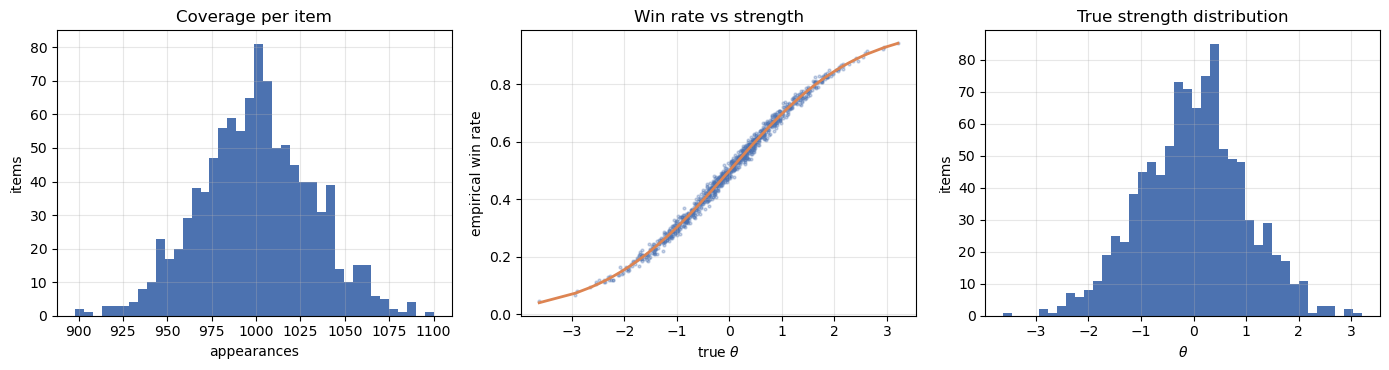

In [18]:
def diagnose(data, plot=True):
    n = data.n_items
    winners, losers = data.pairs[:, 0], data.pairs[:, 1]

    wins = np.bincount(winners, minlength=n)
    losses = np.bincount(losers, minlength=n)
    appearances = wins + losses

    played = appearances > 0
    win_rate = np.divide(wins, appearances, out=np.full(n, np.nan), where=played)

    adj = coo_matrix((np.ones(len(data.pairs)), (winners, losers)), shape=(n, n))
    n_components, _ = connected_components(adj, directed=True, connection="strong")

    lo, hi = np.minimum(winners, losers), np.maximum(winners, losers)
    pairs_seen = len(np.unique(lo * n + hi))
    pairs_possible = n * (n - 1) // 2

    info = {
        "n_items": n,
        "n_comparisons": data.n_comparisons,
        "obs_per_item": appearances.mean(),
        "min_appearances": appearances.min(),
        "never_played": int((appearances == 0).sum()),
        "undefeated": int((played & (losses == 0)).sum()),
        "winless": int((played & (wins == 0)).sum()),
        "n_components": n_components,
        "mle_exists": n_components == 1,
        "pair_coverage": pairs_seen / pairs_possible,
    }

    print(f"{n:,} items, {data.n_comparisons:,} comparisons")
    print(f"  appearances per item : mean {info['obs_per_item']:.0f}, min {info['min_appearances']}")
    print(f"  pair coverage        : {info['pair_coverage']:.1%} ({pairs_seen:,} of {pairs_possible:,})")
    print(f"  undefeated / winless : {info['undefeated']} / {info['winless']}")
    print(f"  strong components    : {n_components}", end="  ")
    print("-> MLE is finite" if info["mle_exists"] else "-> MLE diverges, needs regularization")
    if plot:
        fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))

        ax[0].hist(appearances, bins=40, color="#4C72B0")
        ax[0].set(xlabel="appearances", ylabel="items", title="Coverage per item")

        ax[1].scatter(data.theta, win_rate, s=4, alpha=0.3, color="#4C72B0")
        expected = sigmoid(data.theta[:, None] - data.theta[None, :]).mean(axis=1)
        order = np.argsort(data.theta)
        ax[1].plot(data.theta[order], expected[order], color="#DD8452", lw=2)
        ax[1].set(xlabel=r"true $\theta$", ylabel="empirical win rate", title="Win rate vs strength")

        ax[2].hist(data.theta, bins=40, color="#4C72B0")
        ax[2].set(xlabel=r"$\theta$", ylabel="items", title="True strength distribution")

        plt.tight_layout()
        plt.show()

    return info


info = diagnose(data)

In [19]:
def to_tensors(data, device=DEVICE):
    """Move a BTData's comparison indices onto the compute device."""
    winners = torch.as_tensor(data.pairs[:, 0], device=device)
    losers = torch.as_tensor(data.pairs[:, 1], device=device)
    return winners, losers


def nll(theta, winners, losers):
    """Mean negative log-likelihood of the Bradley-Terry model."""
    return torch.nn.functional.softplus(-(theta[winners] - theta[losers])).mean()


def centered_error(estimate, truth):
    """Mean absolute error after removing the arbitrary additive shift."""
    e = estimate - estimate.mean()
    t = truth - truth.mean()
    return np.abs(e - t).mean()


winners, losers = to_tensors(data)

theta_true = torch.as_tensor(data.theta, device=DEVICE)
theta_zero = torch.zeros(data.n_items, device=DEVICE)

print(f"NLL at true theta : {nll(theta_true, winners, losers).item():.6f}")
print(f"NLL at theta = 0  : {nll(theta_zero, winners, losers).item():.6f}")
print(f"log 2             : {np.log(2):.6f}")

NLL at true theta : 0.541929
NLL at theta = 0  : 0.693147
log 2             : 0.693147


time      : 3.49s  (6.98 ms/iter)
final NLL : 0.641304
MAE       : 0.6507


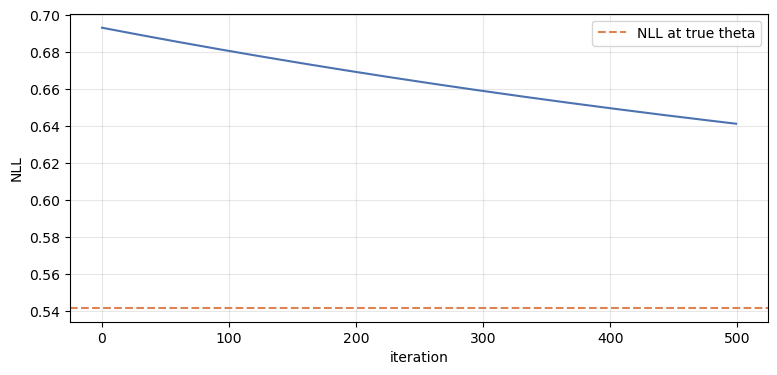

In [20]:
@dataclass
class FitResult:
    theta: np.ndarray
    loss_history: list
    seconds: float
    n_iters: int


def fit_gd(data, lr=1.0, n_iters=500, log_tag=None):
    """Full-batch gradient descent on the Bradley-Terry NLL."""
    winners, losers = to_tensors(data)
    theta = torch.zeros(data.n_items, device=DEVICE, requires_grad=True)

    history = []
    start = time.perf_counter()

    for _ in range(n_iters):
        loss = nll(theta, winners, losers)

        if theta.grad is not None:
            theta.grad.zero_()
        loss.backward()

        with torch.no_grad():
            theta -= lr * theta.grad
            theta -= theta.mean()

        history.append(loss.item())

    elapsed = time.perf_counter() - start

    if log_tag:
        writer = SummaryWriter(LOG_ROOT / f"{log_tag}_{datetime.now():%m%d-%H%M%S}")
        for step, value in enumerate(history):
            writer.add_scalar("nll/train", value, step)
        writer.close()

    return FitResult(theta.detach().cpu().numpy(), history, elapsed, n_iters)


gd = fit_gd(data, lr=1.0, n_iters=500, log_tag="gd_lr1.0")

print(f"time      : {gd.seconds:.2f}s  ({gd.seconds / gd.n_iters * 1000:.2f} ms/iter)")
print(f"final NLL : {gd.loss_history[-1]:.6f}")
print(f"MAE       : {centered_error(gd.theta, data.theta):.4f}")

plt.plot(gd.loss_history, color="#4C72B0")
plt.axhline(nll(theta_true, winners, losers).item(), color="#DD8452", ls="--", label="NLL at true theta")
plt.xlabel("iteration"); plt.ylabel("NLL"); plt.legend(); plt.show()

In [21]:
for lr in [1, 10, 100, 500, 1000, 2000]:
    r = fit_gd(data, lr=lr, n_iters=200)
    print(f"lr={lr:>5}  final NLL {r.loss_history[-1]:.6f}  MAE {centered_error(r.theta, data.theta):.4f}")

lr=    1  final NLL 0.669358  MAE 0.7257
lr=   10  final NLL 0.575524  MAE 0.3994
lr=  100  final NLL 0.540957  MAE 0.0602
lr=  500  final NLL 0.540930  MAE 0.0598
lr= 1000  final NLL 0.540930  MAE 0.0598
lr= 2000  final NLL 0.540930  MAE 0.0598


time      : 3.56s  (7.13 ms/iter)
final NLL : 0.540930
MAE       : 0.0598


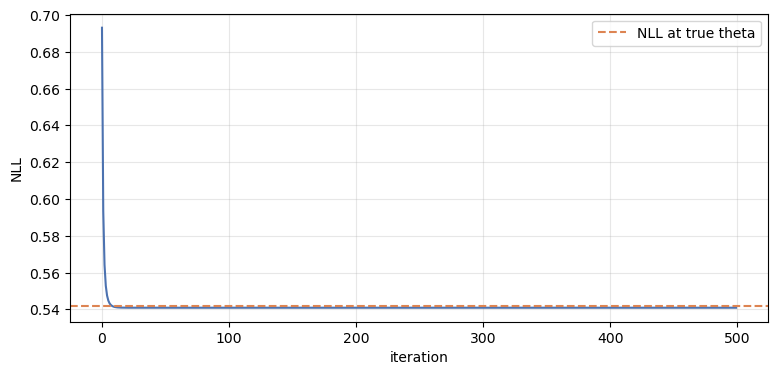

In [22]:
gd = fit_gd(data, lr=1000, n_iters=500, log_tag="gd_lr1000")

print(f"time      : {gd.seconds:.2f}s  ({gd.seconds / gd.n_iters * 1000:.2f} ms/iter)")
print(f"final NLL : {gd.loss_history[-1]:.6f}")
print(f"MAE       : {centered_error(gd.theta, data.theta):.4f}")

plt.plot(gd.loss_history, color="#4C72B0")
plt.axhline(nll(theta_true, winners, losers).item(), color="#DD8452", ls="--", label="NLL at true theta")
plt.xlabel("iteration"); plt.ylabel("NLL"); plt.legend(); plt.show()

In [ ]:
def fit_sgd(data, lr, batch_size, n_epochs=20, seed=SEED, log_tag=None):
    """Mini-batch stochastic gradient descent, reshuffled each epoch."""
    winners, losers = to_tensors(data)
    theta = torch.zeros(data.n_items, device=DEVICE, requires_grad=True)

    m = data.n_comparisons
    n_batches = m // batch_size
    rng = np.random.default_rng(seed)

    history = []
    start = time.perf_counter()

    for _ in range(n_epochs):
        order = torch.as_tensor(rng.permutation(m), device=DEVICE)

        for b in range(n_batches):
            idx = order[b * batch_size:(b + 1) * batch_size]
            loss = nll(theta, winners[idx], losers[idx])

            if theta.grad is not None:
                theta.grad.zero_()
            loss.backward()

            with torch.no_grad():
                theta -= lr * theta.grad
                theta -= theta.mean()

            history.append(loss.item())

    elapsed = time.perf_counter() - start

    if log_tag:
        writer = SummaryWriter(LOG_ROOT / f"{log_tag}_{datetime.now():%m%d-%H%M%S}")
        for step, value in enumerate(history):
            writer.add_scalar("nll/batch", value, step)
        writer.close()

    return FitResult(theta.detach().cpu().numpy(), history, elapsed, n_epochs * n_batches)

target = nll(theta_true, winners, losers).item()
for bs in [1_000, 10_000, 100_000]:
    r = fit_sgd(data, lr=1000, batch_size=bs, n_epochs=20)
    full = nll(torch.as_tensor(r.theta, device=DEVICE), winners, losers).item()
    print(f"bs={bs:>7,}  steps {r.n_iters:>5}  {r.seconds:5.2f}s  "
          f"NLL {full:.6f}  MAE {centered_error(r.theta, data.theta):.4f}")

print(f"{'':>7}  target NLL {target:.6f}")

bs=  1,000  steps 10000   1.29s  NLL 0.697184  MAE 0.8415
bs= 10,000  steps  1000   0.61s  NLL 0.551770  MAE 0.2050
bs=100,000  steps   100   0.31s  NLL 0.541254  MAE 0.0687
         target NLL 0.541929
